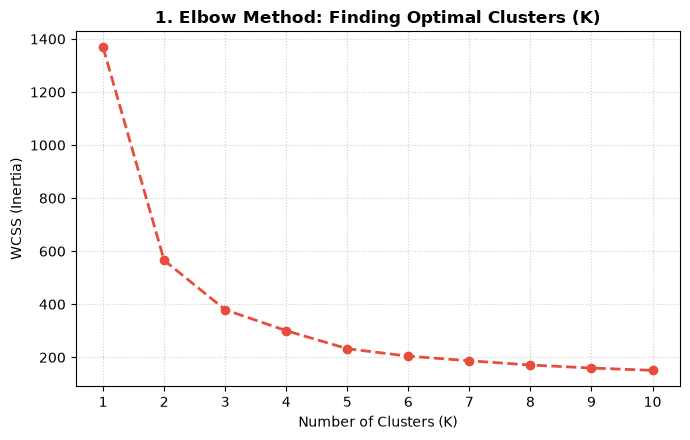

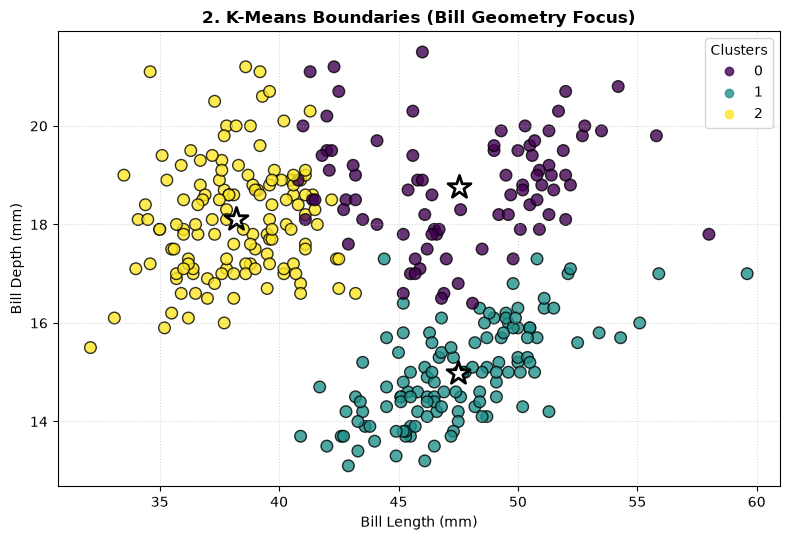

<Figure size 700x450 with 0 Axes>

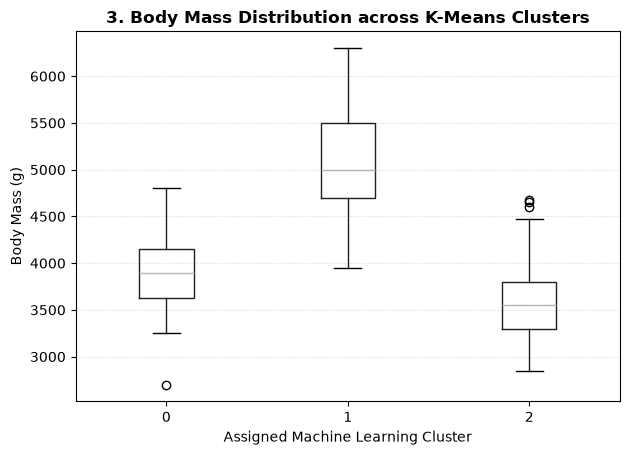

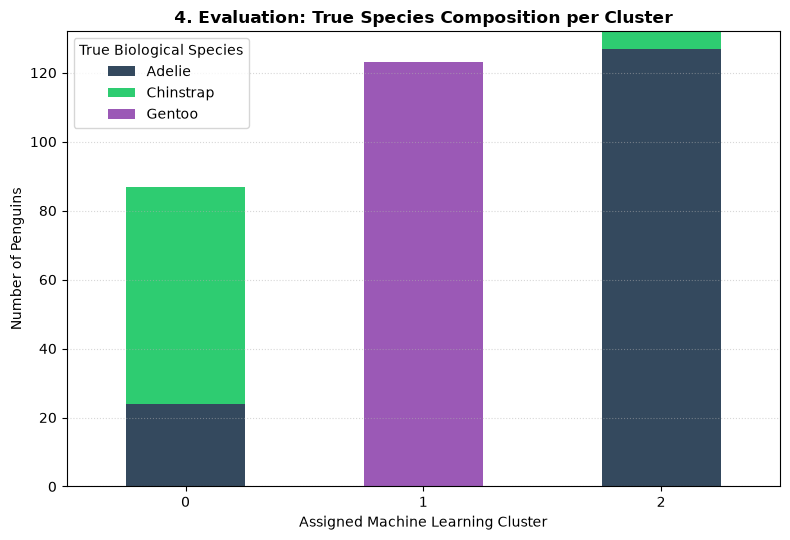

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# =====================================================================
# 1. DATA PROCESSING & MODEL FITTING
# =====================================================================
df = pd.read_csv("penguins.csv")
features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

# Clean by keeping missing gender rows, dropping only missing physics rows
df_cleaned = df.dropna(subset=features).copy()
X = df_cleaned[features]

# Scale features so weights and lengths have equal mathematical impact
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Run optimal K=3
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df_cleaned["cluster"] = kmeans.fit_predict(X_scaled)

# =====================================================================
# GRAPH 1: THE ELBOW METHOD (Pure Matplotlib)
# =====================================================================
wcss = []
k_range = range(1, 11)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=30, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

plt.figure(figsize=(7, 4.5))
plt.plot(k_range, wcss, marker="o", linestyle="--", color="#e74c3c", linewidth=2)
plt.title("1. Elbow Method: Finding Optimal Clusters (K)", fontsize=12, fontweight="bold")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.xticks(k_range)
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

# =====================================================================
# GRAPH 2: 2D CLUSTER BOUNDARIES WITH CENTROIDS (Pure Matplotlib)
# =====================================================================
centroids_raw = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(8, 5.5))
# Using matplotlib's native scatter with c mapping instead of seaborn
scatter = plt.scatter(
    df_cleaned["bill_length_mm"],
    df_cleaned["bill_depth_mm"],
    c=df_cleaned["cluster"],
    cmap="viridis",
    alpha=0.8,
    edgecolor="k",
    s=70
)
# Overlay mathematical centers as large white stars
plt.scatter(
    centroids_raw[:, 0],
    centroids_raw[:, 1],
    s=300,
    c="white",
    marker="*",
    edgecolors="black",
    linewidths=2,
    label="Cluster Centroids"
)
plt.title("2. K-Means Boundaries (Bill Geometry Focus)", fontsize=12, fontweight="bold")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Bill Depth (mm)")
plt.legend(*scatter.legend_elements(), title="Clusters")
plt.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

# =====================================================================
# GRAPH 3: CLUSTER VARIANCE AND SPREAD (Pure Pandas Boxplot)
# =====================================================================
plt.figure(figsize=(7, 4.5))
# Pandas has a built-in boxplot wrapper that uses matplotlib under the hood
df_cleaned.boxplot(column="body_mass_g", by="cluster", grid=False)
plt.title("3. Body Mass Distribution across K-Means Clusters", fontsize=12, fontweight="bold")
plt.suptitle("") # Clears automatic pandas subtitle
plt.xlabel("Assigned Machine Learning Cluster")
plt.ylabel("Body Mass (g)")
plt.grid(True, axis="y", linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

# =====================================================================
# GRAPH 4: TRUTH VERIFICATION CHART (Pure Pandas Plot)
# =====================================================================
crosstab_data = pd.crosstab(df_cleaned["cluster"], df_cleaned["species"])

# Pandas handles stacked bar charts directly using matplotlib
crosstab_data.plot(kind="bar", stacked=True, figsize=(8, 5.5), color=["#34495e", "#2ecc71", "#9b59b6"])
plt.title("4. Evaluation: True Species Composition per Cluster", fontsize=12, fontweight="bold")
plt.xlabel("Assigned Machine Learning Cluster")
plt.ylabel("Number of Penguins")
plt.xticks(rotation=0)
plt.legend(title="True Biological Species")
plt.grid(True, axis="y", linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()
